<a href="https://colab.research.google.com/github/rj3005006-ui/AI-pioneers-internship/blob/main/TASK2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

K-Means Silhouette Score: 0.46
Hierarchical Silhouette Score: 0.447
Variance retained by two PCA components: 0.958


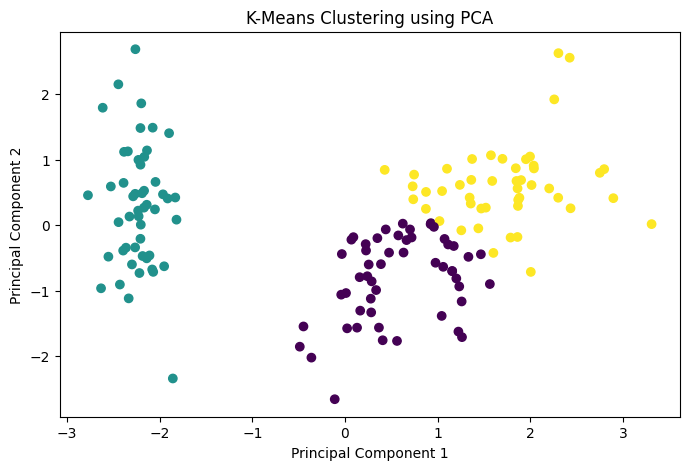


Cross-validation scores: [0.91666667 1.         0.95833333 0.95833333 1.        ]
Mean CV accuracy: 0.967

Best parameters: {'kneighborsclassifier__n_neighbors': 5}
Best CV accuracy: 0.967

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30

Weighted ROC-AUC: 0.993


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV
)
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# -------------------------------
# 1. K-Means Clustering
# -------------------------------
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)
kmeans_labels = kmeans.fit_predict(X_scaled)

kmeans_score = silhouette_score(
    X_scaled, kmeans_labels
)

print("K-Means Silhouette Score:", round(kmeans_score, 3))

# -------------------------------
# 2. Hierarchical Clustering
# -------------------------------
hierarchical = AgglomerativeClustering(
    n_clusters=3
)
hierarchical_labels = hierarchical.fit_predict(X_scaled)

hierarchical_score = silhouette_score(
    X_scaled, hierarchical_labels
)

print(
    "Hierarchical Silhouette Score:",
    round(hierarchical_score, 3)
)

# -------------------------------
# 3. PCA Dimensionality Reduction
# -------------------------------
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(
    "Variance retained by two PCA components:",
    round(sum(pca.explained_variance_ratio_), 3)
)

# Visualize K-Means clusters
plt.figure(figsize=(8, 5))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels
)
plt.title("K-Means Clustering using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

# -------------------------------
# 4. Supervised Model Evaluation
# -------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier()
)

# Cross-validation
cv_scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("\nCross-validation scores:", cv_scores)
print("Mean CV accuracy:", round(cv_scores.mean(), 3))

# Hyperparameter tuning
parameters = {
    "kneighborsclassifier__n_neighbors": [3, 5, 7, 9]
}

search = GridSearchCV(
    model,
    parameters,
    cv=5,
    scoring="accuracy"
)
search.fit(X_train, y_train)

best_model = search.best_estimator_
predictions = best_model.predict(X_test)

print("\nBest parameters:", search.best_params_)
print("Best CV accuracy:", round(search.best_score_, 3))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predictions))

# Classification metrics
print("\nClassification Report:")
print(classification_report(
    y_test,
    predictions,
    target_names=iris.target_names
))

# Multiclass ROC-AUC
probabilities = best_model.predict_proba(X_test)
y_test_binary = label_binarize(
    y_test,
    classes=[0, 1, 2]
)

auc = roc_auc_score(
    y_test_binary,
    probabilities,
    multi_class="ovr",
    average="weighted"
)

print("Weighted ROC-AUC:", round(auc, 3))